EXERCICE 1


In [ ]:
import numpy as np
from hmmlearn.hmm import CategoricalHMM

# Hidden states and observations
states = ["1", "2", "3", "4"]
colors = ["red", "green", "blue"]

# Initial probabilities of the states
start_prob = np.array([1/4, 1/4, 1/4, 1/4])

# Transition probabilities
trans_prob = np.array([
    [0.2, 0.4, 0, 0.4],
    [0.4, 0.2, 0.4, 0],
    [0, 0.4, 0.2, 0.4], 
    [0.4, 0, 0.4, 0.2]
])

# Emission probabilities
emission_prob = np.array([
    [0.7, 0.2, 0.1],
    [0.2, 0.6, 0.2],
    [0.1, 0.3, 0.6],
    [0.5, 0.2, 0.3]
])

# Create the Hidden Markov Model
model = CategoricalHMM(n_components=4, init_params="")
model.startprob_ = start_prob
model.transmat_ = trans_prob
model.emissionprob_ = emission_prob

print("Hidden Markov Model created successfully!")
print("Transition matrix:")
print(model.transmat_)
print("Emission matrix:")
print(model.emissionprob_)

Hidden Markov Model created successfully!
Transition matrix:
[[0.2 0.4 0.  0.4]
 [0.4 0.2 0.4 0. ]
 [0.  0.4 0.2 0.4]
 [0.4 0.  0.4 0.2]]
Emission matrix:
[[0.7 0.2 0.1]
 [0.2 0.6 0.2]
 [0.1 0.3 0.6]
 [0.5 0.2 0.3]]


Now we are gonna determinate the most likely sequence of roomns for this sequence [red,green,blue,blue,red]

In [57]:
import numpy as np
from hmmlearn import hmm

# Hidden states
states = ["1", "2", "3", "4"]
id2state = {
    0: "1",
    1: "2",
    2: "3",
    3: "4"
}
# Initial probabilities
start_probs = np.array([1/4, 1/4, 1/4, 1/4])

# Possible observations
colors = ["red", "green", "blue"]

# Observed colors
observed_colors = [
    "red", "green", "blue", "blue", "red"
]

# Convert colors into numerical values
color2id = {
    "red": 0,
    "green": 1,
    "blue": 2
}

# Convert observed colors into a NumPy array of numerical values for the HMM
X = []
for color in observed_colors:
    X.append([color2id[color]])

data = np.array(X)

# Create an HMM with three hidden states and no automatic parameter initialization
model = hmm.CategoricalHMM(
    n_components=len(states),
    init_params=""
)

model.startprob_ = start_probs
model.transmat_ = trans_prob
model.emissionprob_ = emission_prob

# Decode using Viterbi
logprob, received = model.decode(data, algorithm="viterbi")

print("Observed colors:")
print(observed_colors)

print("\nMost probable sequence of rooms:")
print([id2state[x] for x in received])

print("\nJoint probability:")
print(np.exp(logprob))

Observed colors:
['red', 'green', 'blue', 'blue', 'red']

Most probable sequence of rooms:
['1', '2', '3', '4', '1']

Joint probability:
0.000338688


1b) 

In [58]:
import numpy as np
from hmmlearn import hmm

# Hidden states: test difficulty
states = ["1", "2", "3", "4"]
id2state = {
    0: "1",
    1: "2",
    2: "3",
    3: "4"
}
# Initial probabilities
start_probs = np.array([1/4, 1/4, 1/4, 1/4])

# Possible observations: student grades
colors = ["red", "green", "blue"]

# Observed grades
observed_colors = [
    "red", "green", "blue", "blue", "red"
]

# Convert grades into numerical values
grade2id = {
    "red": 0,
    "green": 1,
    "blue": 2
}

# Transition probabilities
# we have to change the transition probabilities to reflect the new assumption that the student can only move to adjacent rooms
new_trans_prob = np.array([
    [0, 0.5, 0, 0.5],
    [0.5, 0, 0.5, 0],
    [0, 0.5, 0, 0.5], 
    [0.5, 0, 0.5, 0]
])

# Create the Hidden Markov Model
model1 = CategoricalHMM(n_components=4, init_params="")
model1.startprob_ = start_probs
model1.transmat_ = new_trans_prob
model1.emissionprob_ = emission_prob

print("Hidden Markov Model created successfully!")
print("Transition matrix:")
print(model1.transmat_)
print("Emission matrix:")
print(model1.emissionprob_)

# Convert observed colors into a NumPy array of numerical values for the HMM
X = []
for color in observed_colors:
    X.append([color2id[color]])

data = np.array(X)

# Decode using Viterbi
logprob1, received1 = model1.decode(data, algorithm="viterbi")

print("Observed colors:")
print(observed_colors)

print("\nMost probable sequence of rooms, Model 1:")
print([id2state[x] for x in received1])

print("\nJoint probability:")
print(np.exp(logprob1))

Hidden Markov Model created successfully!
Transition matrix:
[[0.  0.5 0.  0.5]
 [0.5 0.  0.5 0. ]
 [0.  0.5 0.  0.5]
 [0.5 0.  0.5 0. ]]
Emission matrix:
[[0.7 0.2 0.1]
 [0.2 0.6 0.2]
 [0.1 0.3 0.6]
 [0.5 0.2 0.3]]
Observed colors:
['red', 'green', 'blue', 'blue', 'red']

Most probable sequence of rooms, Model 1:
['1', '2', '3', '4', '1']

Joint probability:
0.0008268749999999998


For the firts option we have this most probable sequence of rooms:
['1', '2', '3', '4', '1'] with this propability 0.000338688

but now we have this most probable sequence of rooms, 
['1', '2', '3', '4', '1'] with this probabilty 0.0008268749999999998

As we see, we have the same sequence of rooms given that in the first model we have the posibility to change the room about 4/5 and only remain the same 1/5 so is most probable to chance than stay, also in the second model there is no option for remain in the same room so is 100% to move. 

In addition, the sequence is the same because of the distribution of the rooms, for example if we stay in 2, we cannot go to four, so this makes to easy to go to the same room and thats why we have the same sequence of hidden states. 

EXERCICE 2

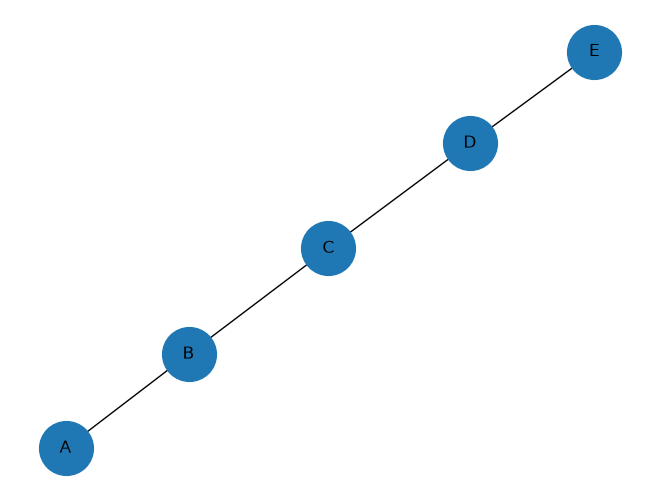

In [51]:
#a)
import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()

G.add_nodes_from(["A", "B", "C", "D", "E"])

G.add_edges_from([
    ("A", "B"),
    ("B", "C"),
    ("C", "D"),
    ("D", "E")
])

nx.draw(G, with_labels=True, node_size=1500)
plt.show()

EXERCICE 3


We are gonna use the Beta distributon to get the probability that a product is defective.

$$
\theta \sim Beta(2,8)
$$

Then we are gonna observed 20 producto in which:  
- 8 are defective.
- 12 are good.

We update the prior using the new data to make the posterior: 

- alpha = 2 + 8 = 10
- beta = 8 + 12 = 20

$$
\theta | data \sim Beta(10,20)
$$

Posterior
Beta mean has this formula ==> alpha / (alpha + beta) becuase we know that beta is to estimates the probabilities

In [52]:
# Prior parameters
alpha = 2
beta = 8

# Prior mean and variance (Beta distribution)
prior_mean = alpha / (alpha + beta)
prior_variance = (alpha * beta) / ((alpha + beta)**2 * (alpha + beta + 1))

print("Prior mean:", prior_mean)
print("Prior variance:", prior_variance)

Prior mean: 0.2
Prior variance: 0.014545454545454545


In [53]:
products = 20
defective = 8
good = products - defective


posterior_alpha = alpha + defective
posterior_beta = beta + good

# Posterior mean
posterior_mean = posterior_alpha / (posterior_alpha + posterior_beta)

print("Posterior distribution: Beta(", posterior_alpha, ",", posterior_beta, ")")
print("Posterior mean:", posterior_mean)

Posterior distribution: Beta( 10 , 20 )
Posterior mean: 0.3333333333333333


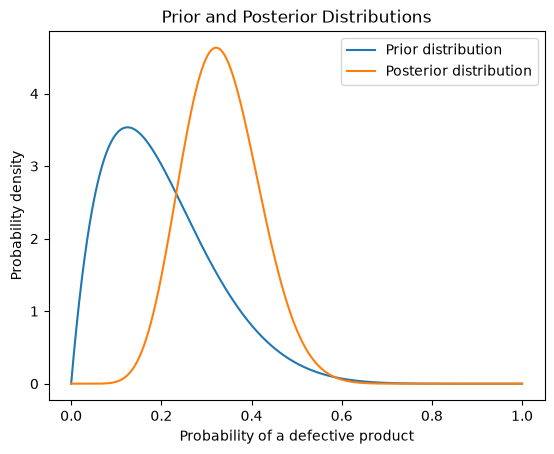

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta as beta_dist

# Values for the prior and posterior distributions
x = np.linspace(0, 1, 1000)

prior_y = beta_dist.pdf(x, a=alpha, b=beta)
posterior_y = beta_dist.pdf(x, a=posterior_alpha, b=posterior_beta)

# Plot the prior distribution
plt.plot(x, prior_y, label="Prior distribution")

# Plot the posterior distribution
plt.plot(x, posterior_y, label="Posterior distribution")

plt.title("Prior and Posterior Distributions")
plt.xlabel("Probability of a defective product")
plt.ylabel("Probability density")
plt.legend()
plt.show()


Posterior distribution: Beta( 13 , 32 )
Posterior mean: 0.28888888888888886


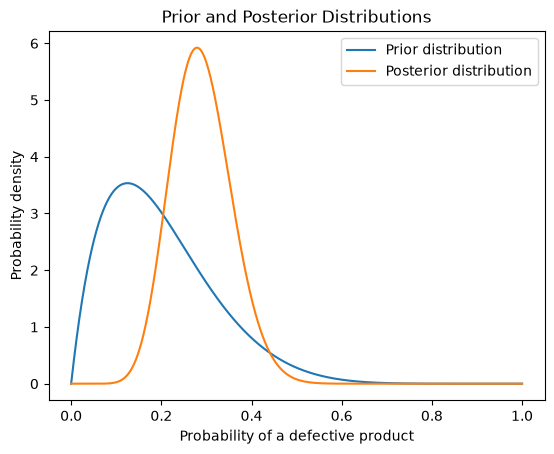

In [59]:
#3b)
# first batch 
posterior_alpha = 10
posterior_beta = 20

# second batch
products_2 = 15
defective_2 = 3
good_2 = products_2 - defective_2

# after observing both batches
posterior_alpha_2 = posterior_alpha + defective_2
posterior_beta_2 = posterior_beta + good_2

# Posterior mean
posterior_mean_2 = posterior_alpha_2 / (posterior_alpha_2 + posterior_beta_2)

print("Posterior distribution: Beta(", posterior_alpha_2, ",", posterior_beta_2, ")")
print("Posterior mean:", posterior_mean_2)

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta as beta_dist

# Values for the prior and posterior distributions
x = np.linspace(0, 1, 1000)

prior_y = beta_dist.pdf(x, a=alpha, b=beta)
posterior_y = beta_dist.pdf(x, a=posterior_alpha_2, b=posterior_beta_2)

# Plot the prior distribution
plt.plot(x, prior_y, label="Prior distribution")

# Plot the posterior distribution
plt.plot(x, posterior_y, label="Posterior distribution")

plt.title("Prior and Posterior Distributions")
plt.xlabel("Probability of a defective product")
plt.ylabel("Probability density")
plt.legend()
plt.show()


Posterior distribution: Beta( 5 , 20 )
Posterior mean: 0.2


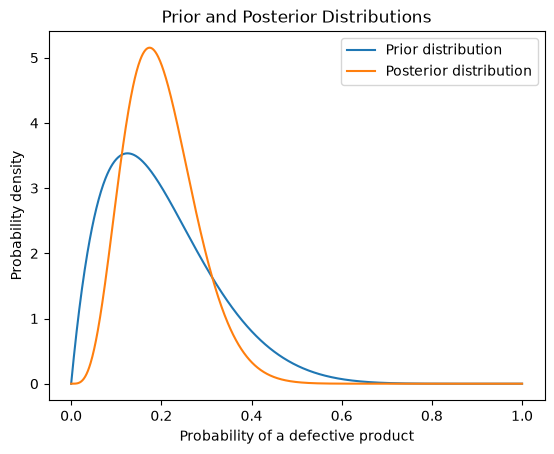

In [60]:
#3c
# initial prior parameters
initial_alpha = 2
initial_beta = 8

# second batch
products_3 = 15
defective_3 = 3
good_3 = products_3 - defective_3

# after observing the second batch only and not the first batch
posterior_alpha_3 = initial_alpha + defective_3
posterior_beta_3 = initial_beta + good_3

# Posterior mean
posterior_mean_3 = posterior_alpha_3 / (posterior_alpha_3 + posterior_beta_3)

print("Posterior distribution: Beta(", posterior_alpha_3, ",", posterior_beta_3, ")")
print("Posterior mean:", posterior_mean_3)


import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta as beta_dist

# Values for the prior and posterior distributions
x = np.linspace(0, 1, 1000)

prior_y = beta_dist.pdf(x, a=alpha, b=beta)
posterior_y = beta_dist.pdf(x, a=posterior_alpha_3, b=posterior_beta_3)

# Plot the prior distribution
plt.plot(x, prior_y, label="Prior distribution")

# Plot the posterior distribution
plt.plot(x, posterior_y, label="Posterior distribution")

plt.title("Prior and Posterior Distributions")
plt.xlabel("Probability of a defective product")
plt.ylabel("Probability density")
plt.legend()
plt.show()

Difference between b and c

In the first one, we use both batches so we finally have 35 products:
the posterior is Beta(13,32) and mean = 28.89%

and for the second one we use only the second batch 15 products:
and the posterior is Beta(5,20) and a mean of 20%

The results are differents because we use different data, in b we have more information because we have 2 batches so is more concentrated than the second one because we ignore the first batch.
